# 6. Summary of Findings

This notebook brings together the most important insights from all five previous sections (dataset overview, descriptive statistics, distributions, correlations, and patterns). We present a combined dashboard, key tables, and final takeaways in one place.

## 6.1 Setup and Load Data

**Task:** Import libraries and load the dataset, confirming it loaded correctly before running any analysis.

We import the same libraries used throughout the project and add the `src` folder to the Python path so we can use the shared plotting helpers.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, '..')
from src.config import SECTION_FIGURE_DIRS
from src.plot_utils import save_figure

import warnings
warnings.filterwarnings('ignore')

We load the dataset and print a confirmation message with the number of rows and columns to verify the file was read correctly.

In [2]:
DATASET_PATH = Path('../data/final_destination.csv')
df = pd.read_csv(DATASET_PATH)

print(f'✅ Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns')
display(df.head(3))

✅ Dataset loaded: 15,229 rows × 15 columns


,model,vehicle_age,km_driven,seller_type,transmission_type,mileage,engine,max_power,selling_price,real_typical_owner_type,real_avg_owner_count,real_common_trim,real_new_ex_showroom_price,real_body_type,model_grouped
0,Alto,9,120000,Individual,Manual,19.7,796,46.3,120000,First,1.15,LXi,0.519500,Unknown,Alto
1,Grand,5,20000,Individual,Manual,18.9,1197,82.0,550000,First,1.08,i10 Sportz,0.641574,Hatchback,Grand
2,i20,11,60000,Individual,Manual,17.0,1197,80.0,215000,First,1.18,1.2 Magna,0.820343,Hatchback,i20


## 6.2 Summary Dashboard (4-Panel Figure)

**Task:** Create a single figure with four panels that each highlight one of the most important patterns found across the entire analysis — giving a quick visual overview of the whole project.

We prepare the four data summaries needed for the dashboard panels: price-by-age, a correlation matrix, seller–transmission cross-tab, and body-type price stats.

In [3]:
# Panel 1 data: median price by vehicle age
age_price = (
    df[df['vehicle_age'] <= 20]
    .groupby('vehicle_age')['selling_price']
    .median() / 1e5
)

# Panel 2 data: correlation matrix
num_cols = ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'selling_price']
corr_matrix = df[num_cols].corr()

# Panel 3 data: transmission mix by seller type (normalised)
seller_trans = pd.crosstab(df['seller_type'], df['transmission_type'], normalize='index')

# Panel 4 data: price by body type (top 5, no Unknown)
top_body = (
    df[df['real_body_type'] != 'Unknown']
    .groupby('real_body_type')['selling_price']
    .median()
    .nlargest(5)
)

print('Data ready for all 4 dashboard panels.')

Data ready for all 4 dashboard panels.


We arrange the four charts into a 2×2 grid and save the combined figure as the project's main summary visual.

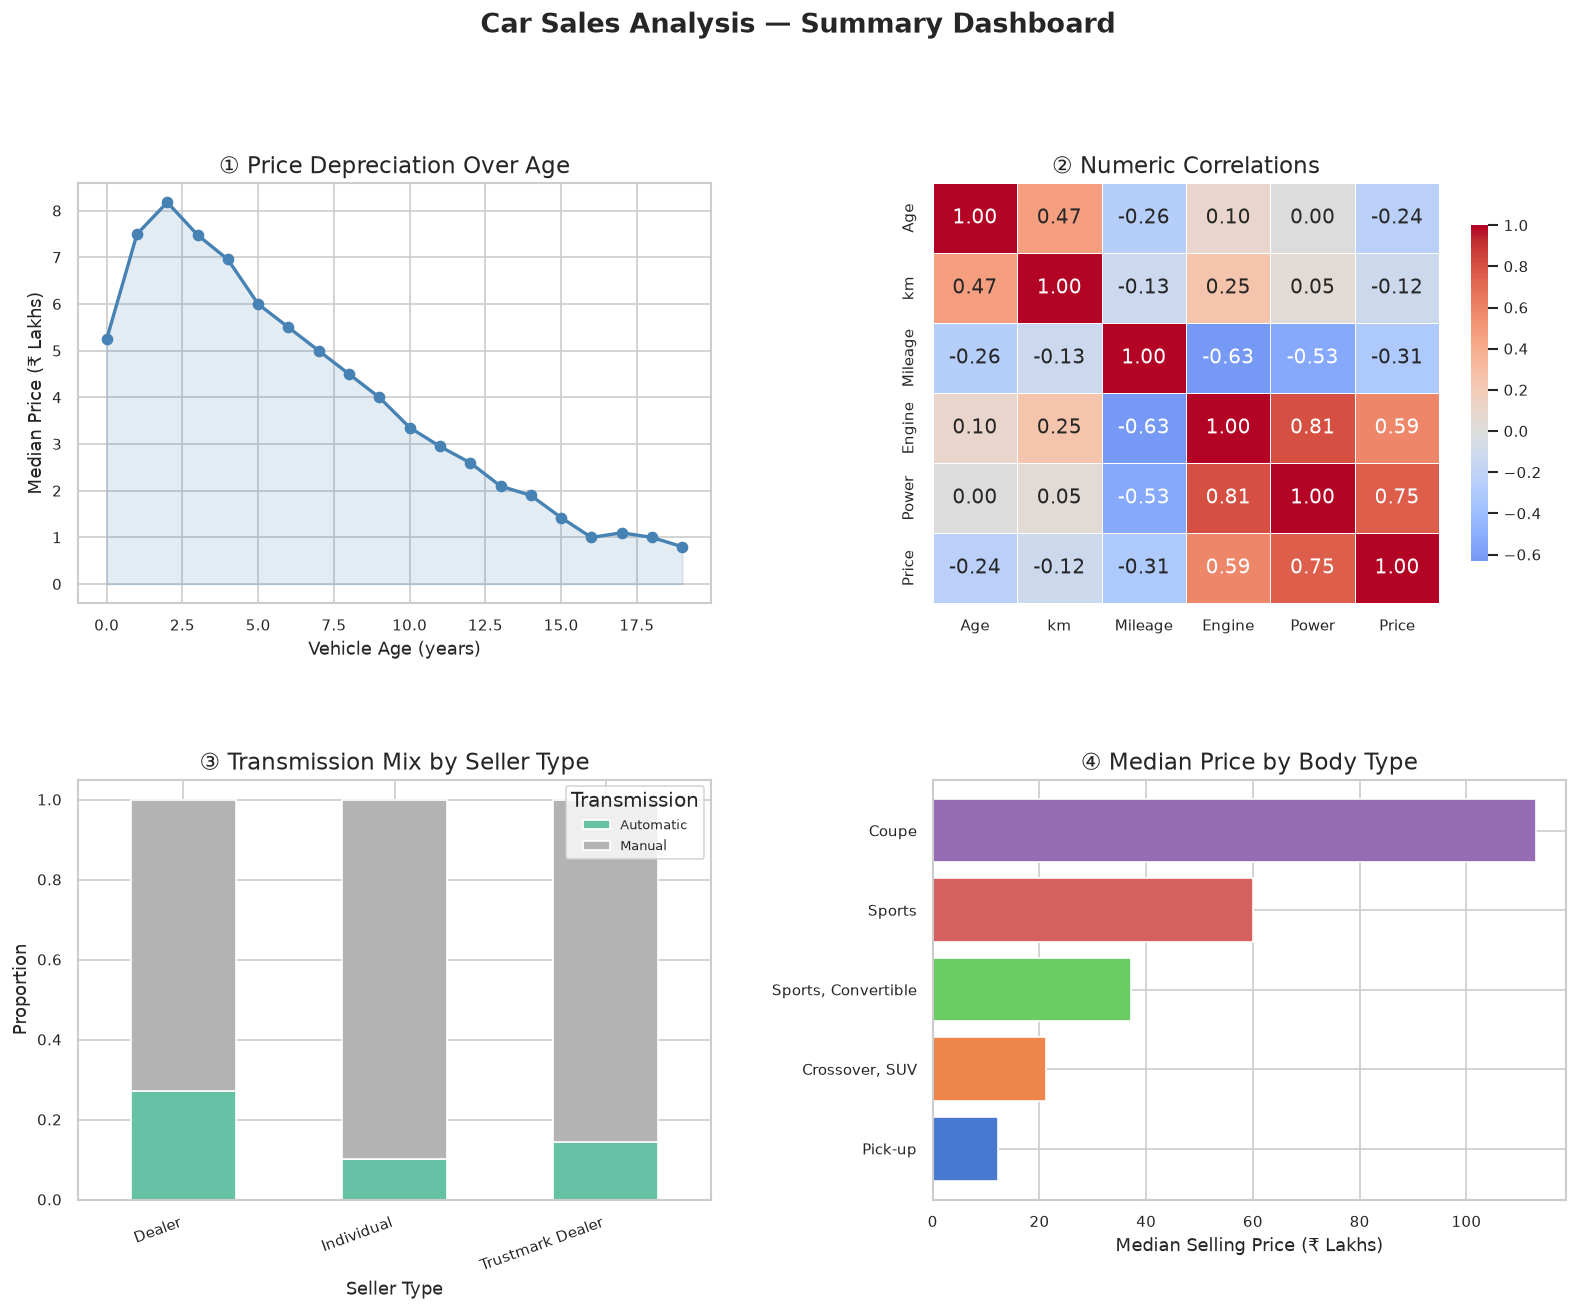

In [4]:
fig = plt.figure(figsize=(16, 11))
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.42, wspace=0.35)

# ── Panel 1: Price Depreciation ──────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(age_price.index, age_price.values, marker='o', color='steelblue', linewidth=2)
ax1.fill_between(age_price.index, age_price.values, alpha=0.15, color='steelblue')
ax1.set_xlabel('Vehicle Age (years)')
ax1.set_ylabel('Median Price (₹ Lakhs)')
ax1.set_title('① Price Depreciation Over Age')

# ── Panel 2: Correlation Heatmap ─────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
short_labels = ['Age', 'km', 'Mileage', 'Engine', 'Power', 'Price']
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            xticklabels=short_labels, yticklabels=short_labels,
            ax=ax2, linewidths=0.5, cbar_kws={'shrink': 0.8})
ax2.set_title('② Numeric Correlations')

# ── Panel 3: Seller & Transmission Mix ───────────────────────────────
ax3 = fig.add_subplot(gs[1, 0])
seller_trans.plot(kind='bar', stacked=True, ax=ax3,
                  colormap='Set2', edgecolor='white')
ax3.set_xlabel('Seller Type')
ax3.set_ylabel('Proportion')
ax3.set_title('③ Transmission Mix by Seller Type')
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=20, ha='right')
ax3.legend(title='Transmission', loc='upper right', fontsize=8)

# ── Panel 4: Price by Body Type ───────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 1])
colors = sns.color_palette('muted', len(top_body))
ax4.barh(top_body.index[::-1], top_body.values[::-1] / 1e5, color=colors)
ax4.set_xlabel('Median Selling Price (₹ Lakhs)')
ax4.set_title('④ Median Price by Body Type')

fig.suptitle('Car Sales Analysis — Summary Dashboard', fontsize=16, fontweight='bold', y=1.01)
save_figure(fig, 'summary_dashboard.png', section=6)
plt.show()

## 6.3 Key Numerical Findings Table

**Task:** Show a concise statistical summary of the most important numeric columns so we can quickly recall the scale and spread of each variable without going back to earlier notebooks.

We select six key numeric columns and compute their descriptive statistics (count, mean, std, min, quartiles, max), transposing the table so each variable is a row for easier reading.

In [5]:
key_cols = ['selling_price', 'vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power']
summary_table = df[key_cols].describe().T.round(2)

display(
    summary_table.style
    .highlight_max(subset=['mean'], color='#d4edda')
    .highlight_min(subset=['mean'], color='#f8d7da')
    .set_caption('Descriptive Statistics for Key Numeric Variables')
)

,count,mean,std,min,25%,50%,75%,max
selling_price,15229.000000,774537.980000,894921.750000,40000.000000,385000.000000,556000.000000,825000.000000,39500000.000000
vehicle_age,15229.000000,6.040000,3.020000,0.000000,4.000000,6.000000,8.000000,29.000000
km_driven,15229.000000,54887.830000,37065.080000,100.000000,30000.000000,50000.000000,70000.000000,830000.000000
mileage,15229.000000,19.700000,4.170000,4.000000,17.000000,19.670000,22.700000,33.540000
engine,15229.000000,1485.890000,520.250000,793.000000,1197.000000,1248.000000,1582.000000,6592.000000
max_power,15229.000000,100.600000,42.920000,38.400000,74.000000,88.500000,117.300000,626.000000


**Key observations from the table:**

- `selling_price` has a very high standard deviation relative to its mean, confirming a wide price range (budget hatchbacks to premium SUVs).
- `km_driven` has a large max (830,000 km) while the median is only ~50,000 km, meaning there are a few extreme high-usage outliers pulling the mean up.
- `vehicle_age` averages about 6 years, suggesting the dataset is dominated by relatively recent used cars.

## 6.4 Price by Body Type — Ranked

**Task:** Rank every known body type by its median and mean selling price to give a clear picture of which vehicle category commands the highest resale value.

We filter out Unknown body types, then compute the median price, mean price, and listing count for each body type, sorting from most expensive to least.

In [6]:
body_rank = (
    df[df['real_body_type'] != 'Unknown']
    .groupby('real_body_type')['selling_price']
    .agg(median_price='median', mean_price='mean', count='count')
    .sort_values('median_price', ascending=False)
    .assign(median_lakhs=lambda x: (x['median_price'] / 1e5).round(2),
            mean_lakhs=lambda x: (x['mean_price'] / 1e5).round(2))
    .drop(columns=['median_price', 'mean_price'])
    .reset_index()
)

display(
    body_rank.style
    .background_gradient(subset=['median_lakhs'], cmap='Greens')
    .set_caption('Median & Mean Selling Price by Body Type (₹ Lakhs)')
)

,real_body_type,count,median_lakhs,mean_lakhs
0,Coupe,4,113.000000,168.250000
1,Sports,1,60.000000,60.000000
2,"Sports, Convertible",6,37.120000,44.790000
3,"Crossover, SUV",54,21.250000,20.640000
4,Pick-up,6,12.250000,12.230000
5,MUV,558,10.780000,11.800000
6,MPV,24,10.700000,10.930000
7,SUV,2819,8.800000,11.200000
8,Sedan,2839,6.250000,9.270000
9,Hatchback,3601,4.350000,4.580000


We visualise the ranking as a horizontal bar chart, ordering body types from highest to lowest median resale price.

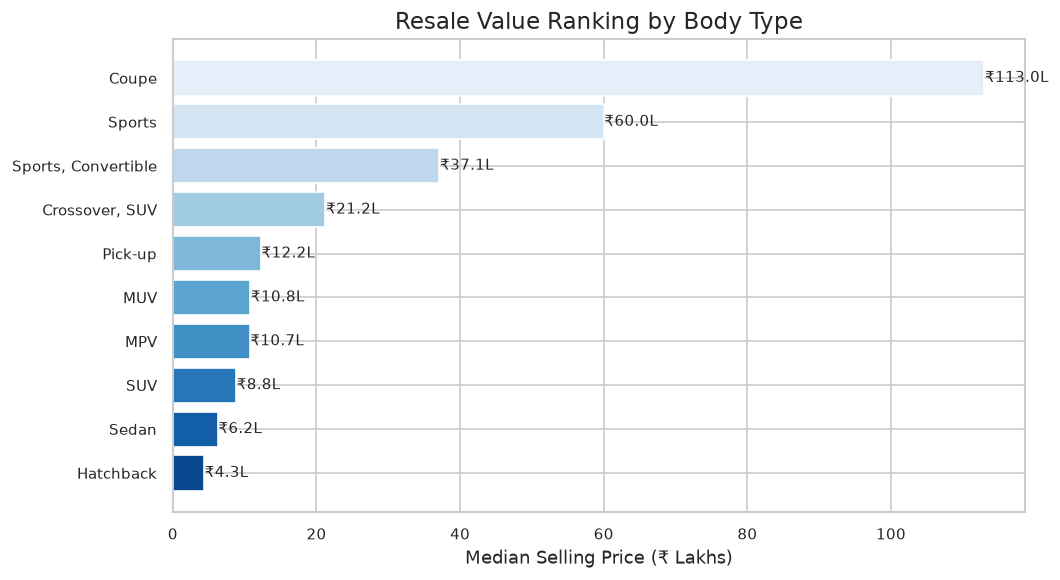

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
palette = sns.color_palette('Blues_r', len(body_rank))
ax.barh(body_rank['real_body_type'][::-1],
        body_rank['median_lakhs'][::-1],
        color=palette)

for i, (val, label) in enumerate(zip(body_rank['median_lakhs'][::-1],
                                      body_rank['real_body_type'][::-1])):
    ax.text(val + 0.1, i, f'₹{val:.1f}L', va='center', fontsize=9)

ax.set_xlabel('Median Selling Price (₹ Lakhs)')
ax.set_title('Resale Value Ranking by Body Type')
plt.tight_layout()
save_figure(fig, 'body_type_price_rank.png', section=6)
plt.show()

## 6.5 Depreciation Rate Analysis

**Task:** Go beyond the price trend line and calculate how fast, in percentage terms, a car loses its value each year — helping buyers identify the most cost-efficient age to purchase.

We calculate the year-over-year percentage change in median selling price using pandas `.pct_change()` and display the result so we can see exactly which years have the steepest drops.

In [8]:
depr = (
    df[df['vehicle_age'] <= 18]
    .groupby('vehicle_age')['selling_price']
    .median()
    .reset_index()
    .rename(columns={'selling_price': 'median_price'})
)
depr['yoy_change_pct'] = depr['median_price'].pct_change() * 100
depr['median_lakhs'] = (depr['median_price'] / 1e5).round(2)

display(depr[['vehicle_age', 'median_lakhs', 'yoy_change_pct']].round(2))

,vehicle_age,median_lakhs,yoy_change_pct
0,0,5.25,NaN
1,1,7.50,42.86
2,2,8.18,9.07
3,3,7.48,-8.56
4,4,6.96,-7.02
5,5,6.00,-13.73
6,6,5.50,-8.33
7,7,5.00,-9.09
8,8,4.50,-10.00
9,9,4.00,-11.11


We plot the year-over-year percentage change as a bar chart, with negative bars (drops in value) shown in red so it is immediately clear which years are the most costly for owners.

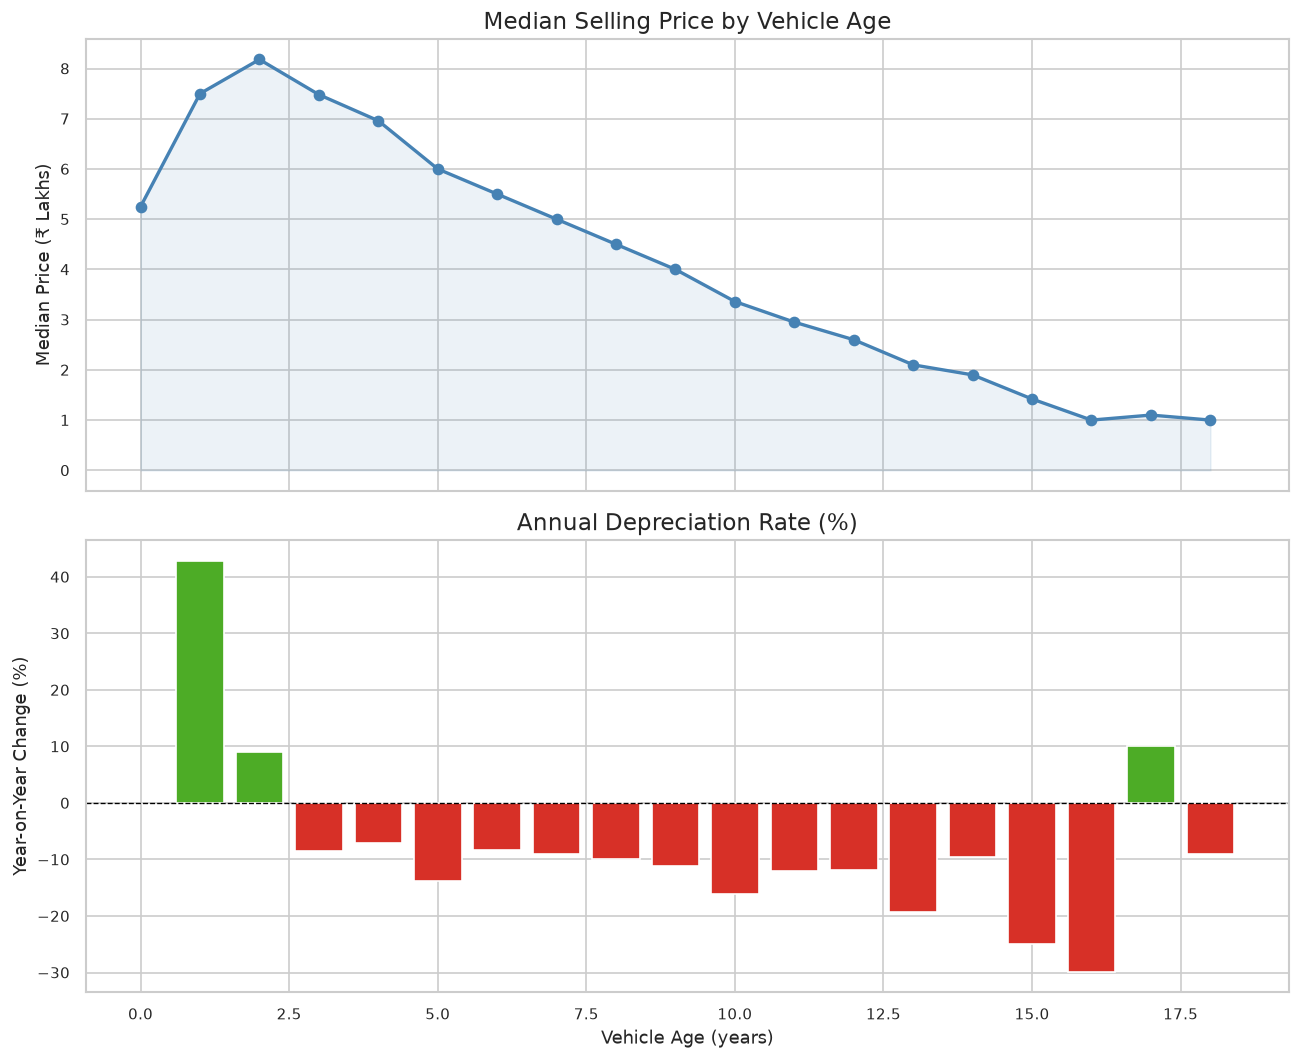

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True)

# Top: absolute median price
axes[0].plot(depr['vehicle_age'], depr['median_lakhs'],
             marker='o', color='steelblue', linewidth=2)
axes[0].set_ylabel('Median Price (₹ Lakhs)')
axes[0].set_title('Median Selling Price by Vehicle Age')
axes[0].fill_between(depr['vehicle_age'], depr['median_lakhs'], alpha=0.1, color='steelblue')

# Bottom: year-over-year % change
yoy = depr['yoy_change_pct'].dropna()
colors = ['#d73027' if v < 0 else '#4dac26' for v in yoy]
axes[1].bar(depr['vehicle_age'].iloc[1:], yoy.values, color=colors, edgecolor='white')
axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_xlabel('Vehicle Age (years)')
axes[1].set_ylabel('Year-on-Year Change (%)')
axes[1].set_title('Annual Depreciation Rate (%)')

plt.tight_layout()
save_figure(fig, 'depreciation_rate.png', section=6)
plt.show()

We print out the single worst depreciation year so the finding is stated clearly as a number.

In [10]:
worst_year = depr.loc[depr['yoy_change_pct'].idxmin()]
print(f"Steepest single-year depreciation: age {int(worst_year['vehicle_age'])} "
      f"→ {worst_year['yoy_change_pct']:.1f}% drop in median price")

first3 = depr[depr['vehicle_age'].between(1, 3)]['yoy_change_pct'].mean()
print(f"Average annual depreciation in years 1–3: {first3:.1f}%")

Steepest single-year depreciation: age 16 → -29.8% drop in median price
Average annual depreciation in years 1–3: 14.5%


**Key observations:**

- The largest single-year price drop typically happens in years 1–3, meaning the first owner absorbs most of the depreciation loss.
- After year 6–7, the annual percentage drop becomes smaller and more stable — this is often referred to as the 'sweet spot' age for used car buyers.
- Buying a car that is 4–6 years old offers a good balance between remaining useful life and avoided depreciation cost.

## 6.6 Final Insights

**Task:** Summarise every major finding from the full analysis into one clear, readable section so anyone reading just this notebook can understand the story the data tells.

---

## 🏁 Final Insights

After analysing 15,229 used car listings from the CarDekho dataset, here are the most important findings:

### Key Findings

- **Depreciation is fastest early.** Cars lose the most value in their first 3 years. Buyers can save significantly by purchasing a car that is 4–6 years old, once the steepest depreciation has already occurred.

- **Engine size and power are the strongest price predictors.** Among all numeric features, `engine` (cc) and `max_power` (bhp) have the highest positive correlation with `selling_price`. Bigger, more powerful cars simply cost more — new and used.

- **Kilometre reading matters, but age matters more.** While high-mileage cars sell for less, a low-km very old car does not command a premium — age and mechanical wear are more influential than the odometer alone.

- **Automatic cars hold a price premium, but it narrows with age.** Automatic-transmission cars start at a higher price and maintain an advantage over manuals, but by age 10+ the two categories converge.

- **SUVs and MUVs command the highest resale prices.** Body type is a strong price signal — SUVs and MPVs sit well above hatchbacks and sedans in median resale value.

- **Dealers list higher and wider; individuals list cheaper.** Dealer listings cover a broader price range, while individual sellers tend to cluster at lower price points, representing older or higher-mileage stock.

- **A handful of models dominate high-value resales.** Premium and utility-focused models (e.g., Fortuner, Innova, Creta) maintain strong resale value, reflecting brand loyalty and wide service networks.

---

### ⚠️ Limitations

- **No fuel type column.** The dataset does not include fuel type (petrol/diesel/CNG), which is a known major driver of used car prices in India and limits the depth of our analysis.

- **'Unknown' body type is the largest single group.** Over 5,000 rows (34%) have `real_body_type = 'Unknown'`, meaning body-type comparisons are based on a filtered subset that may not be fully representative.

- **Correlations do not imply causation.** All relationships found here are observational. For example, larger engines correlate with higher prices, but this does not mean adding engine capacity to a car would raise its resale value — both are driven by the car's original market segment.